# 5. Compare the four Environment A configurations

This notebook compares four representations on the same user-days: M0 has 41 technical features; M1 adds raw organisational encodings for 123 features; M2 adds 18 curated features for 59 in total; and M3 uses the corresponding shuffled context block, also giving 59 features.

**Inputs:** the technical table from Notebook 2; the split and context tables from Notebook 3; and the policy, shared modelling module, baseline scores and feature list from Notebook 4. Organisational records from Notebook 1 support the optional role and department summaries.

M0 scores are reused. M1–M3 are fitted separately through the shared functions and recorded settings. The primary comparison follows the detector and alert policy saved by Notebook 4.

**Outputs:** configuration scores, fixed-budget and matched-recall comparisons, paired intervals, budget curves, account summaries, validation ablations, explanation outputs, subgroup tables and `verdict.json`.

The supporting analyses do not select a replacement primary model. The recorded Environment A result remains H1 not supported.

*Documentation copy, 8 November 2026. Notes edited for clarity; code, saved outputs and execution metadata are unchanged. This copy has not been rerun.*


In [1]:
# ============================================================
# 0. Setup — load ALL upstream artefacts; import shared logic
# ============================================================
import os, glob, json, random, time, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED)
warnings.filterwarnings("ignore")
WORK = "/kaggle/working"
T0 = time.time()

def find(pattern, required=True, what=""):
    hits = glob.glob(f"/kaggle/input/**/{pattern}", recursive=True)
    assert hits or not required, f"Required input not attached: {pattern} ({what})"
    return hits[0] if hits else None

P_FEATS  = find("features_cyberlog.parquet", what="NB2 output")
P_SPLIT  = find("split_definition.json",     what="NB3 output")
P_POLICY = find("threshold_policy.json",     what="NB4 output")
P_UTILS  = find("modelling_utils.py",        what="NB4 output")
P_FLIST  = find("m0_feature_list.json",      what="NB4 output")
P_SCORES = find("scores_m0.parquet",         what="NB4 output")
P_CTX = {m: find(f"context_{m}.parquet", what="NB3 output")
         for m in ("curated", "rawcat", "shuffled")}
P_LDAP = find("ldap_monthly.parquet", required=False, what="NB1 output (optional, subgroup analysis)")
for k, v in [("features", P_FEATS), ("split", P_SPLIT), ("policy", P_POLICY),
             ("utils", P_UTILS), ("scores_m0", P_SCORES), ("ldap", P_LDAP)]:
    print(f"{k:10s}: {v}")

# --- shared logic: import NB4's file VERBATIM; record its hash for provenance ---
import importlib.util
spec = importlib.util.spec_from_file_location("modelling_utils", P_UTILS)
mu = importlib.util.module_from_spec(spec)
spec.loader.exec_module(mu)
UTILS_SHA = hashlib.sha256(open(P_UTILS, "rb").read()).hexdigest()[:16]
print(f"\nmodelling_utils.py imported from NB4 output | sha256[:16]={UTILS_SHA}")

# --- frozen policy (chosen in NB4 on validation; NB5 never re-chooses) ---
POLICY = json.load(open(P_POLICY))
DET, K, K_GRID = POLICY["detector"], float(POLICY["k_pct"]), POLICY["k_grid"]
assert DET in ("if", "ae", "ens") and K in K_GRID
print(f"FROZEN policy: detector={DET}, k={K}% (grid {K_GRID})")
print(f"policy amendment on file: {'v2_amendment' in POLICY}")

SPLIT = json.load(open(P_SPLIT))
feats = pd.read_parquet(P_FEATS)
feats["user"] = feats["user"].astype(str)
feats["day"]  = pd.to_datetime(feats["day"])
LABEL_COL = next(c for c in ("label", "is_malicious", "y") if c in feats.columns)

d = feats["day"]
feats["partition"] = np.select(
    [(d >= SPLIT["train_start"]) & (d <= SPLIT["train_end"]),
     (d >= SPLIT["val_start"])   & (d <= SPLIT["val_end"]),
     (d >= SPLIT["test_start"])  & (d <= SPLIT["test_end"])],
    ["train", "val", "test"], default="drop")
lab = feats.groupby("partition")[LABEL_COL].sum().astype(int)
assert int(lab.get("train", 0)) == 0, "benign-train premise violated — stop."
feats = feats[feats["partition"] != "drop"].reset_index(drop=True)
MASK = {p: (feats["partition"] == p).to_numpy() for p in ("train", "val", "test")}
print(f"\nspine: {len(feats):,} user-days | malicious: "
      f"val {int(lab.get('val', 0))}, test {int(lab.get('test', 0))}")

# --- M0 scores: reuse NB4's committed output (M0 is NOT refitted here) ---
scores_m0 = pd.read_parquet(P_SCORES)
scores_m0["user"] = scores_m0["user"].astype(str)
scores_m0["day"] = pd.to_datetime(scores_m0["day"])
sm0 = feats[["user", "day"]].merge(scores_m0, on=["user", "day"], how="left")
assert sm0[f"score_{DET}"].notna().all(), "scores_m0 does not cover the spine"
print(f"M0 scores aligned to spine from NB4 output ({len(sm0):,} rows)")

features  : /kaggle/input/notebooks/thandondhlovu10/2-feature-engineering/features_cyberlog.parquet
split     : /kaggle/input/notebooks/thandondhlovu10/3-synthetic-organisational-bi/split_definition.json
policy    : /kaggle/input/notebooks/thandondhlovu10/4-cyber-log-only-baseline-model/threshold_policy.json
utils     : /kaggle/input/notebooks/thandondhlovu10/4-cyber-log-only-baseline-model/modelling_utils.py
scores_m0 : /kaggle/input/notebooks/thandondhlovu10/4-cyber-log-only-baseline-model/scores_m0.parquet
ldap      : None

modelling_utils.py imported from NB4 output | sha256[:16]=147d19b0977c79e8
FROZEN policy: detector=if, k=1.0% (grid [0.05, 0.1, 0.25, 0.5, 1.0, 2.0])
policy amendment on file: True

spine: 1,393,997 user-days | malicious: val 40, test 38
M0 scores aligned to spine from NB4 output (1,393,997 rows)


In [2]:
# ============================================================
# 1. Feature matrices — M0 list + context joins (M1/M2/M3)
# ============================================================
M0_FEATURES = json.load(open(P_FLIST))
missing = [c for c in M0_FEATURES if c not in feats.columns]
assert not missing, f"M0 feature list mismatch vs features file: {missing}"

CTX, CTX_COLS = {}, {}
for m, p in P_CTX.items():
    c = pd.read_parquet(p)
    c["user"] = c["user"].astype(str)
    c["day"] = pd.to_datetime(c["day"])
    bad = [col for col in c.columns if "label" in col or "insider" in col]
    assert not bad, f"context_{m} carries label-like columns: {bad}"
    assert not c.duplicated(["user", "day"]).any(), f"context_{m}: duplicate (user, day)"
    cols = [col for col in c.columns if col not in ("user", "day")]
    c[cols] = c[cols].astype("float32")
    CTX[m], CTX_COLS[m] = c, cols
    print(f"context_{m}: {len(cols)} feature cols")

CONFIGS = {"M0": None, "M1": "rawcat", "M2": "curated", "M3": "shuffled"}

def build_frame(ctx_name):
    """M0 features (+ context features for M1/M2/M3), aligned to the spine."""
    base = feats[["user", "day"] + M0_FEATURES]
    if ctx_name is None:
        return base, list(M0_FEATURES)
    merged = base.merge(CTX[ctx_name], on=["user", "day"], how="inner")
    assert len(merged) == len(base), (
        f"context_{ctx_name} does not cover the spine "
        f"({len(merged):,} vs {len(base):,})")
    return merged, M0_FEATURES + CTX_COLS[ctx_name]

for cfg, ctx in CONFIGS.items():
    n = len(M0_FEATURES) + (len(CTX_COLS[ctx]) if ctx else 0)
    print(f"{cfg}: {n} features ({'cyber-log only' if ctx is None else 'cyber-log + ' + ctx})")

context_curated: 18 feature cols
context_rawcat: 82 feature cols
context_shuffled: 18 feature cols
M0: 41 features (cyber-log only)
M1: 123 features (cyber-log + rawcat)
M2: 59 features (cyber-log + curated)
M3: 59 features (cyber-log + shuffled)


## 2. Fit and score M1–M3

Each context configuration combines the M0 technical feature list with its own context columns. The shared `fit_detectors` and `score_detectors` functions fit on training data and produce the scores used below. M0 retains its saved scores rather than being refitted.

M3 uses the same computational path as M2 but changes the organisational assignments. A favourable M3 result would prompt investigation of the control and representation; it would not automatically establish leakage.


In [3]:
# ============================================================
# 2. Fit & score M1–M3 (train only, via shared utils); M0 reused
# ============================================================
import joblib

SCORES = {"M0": {det: sm0[f"score_{det}"].to_numpy() for det in ("if", "ae", "ens")}}
FITTED = {}
for cfg, ctx in CONFIGS.items():
    if ctx is None:
        continue
    t = time.time()
    frame, cols = build_frame(ctx)
    X = mu.prepare_matrix(frame, cols)
    models = mu.fit_detectors(X[MASK["train"]], seed=SEED)
    SCORES[cfg] = mu.score_detectors(models, X)
    FITTED[cfg] = models
    joblib.dump(models["iforest"], f"{WORK}/{cfg.lower()}_iforest.joblib")
    print(f"{cfg}: fit+score in {time.time()-t:,.0f}s "
          f"({X.shape[1]} features, {int(MASK['train'].sum()):,} train rows)")
    del frame, X

scores_all = feats[["user", "day", "partition"]].copy()
scores_all["label"] = feats[LABEL_COL].astype("int8")
for cfg in CONFIGS:
    for det in ("if", "ae", "ens"):
        scores_all[f"{cfg}_{det}"] = np.asarray(SCORES[cfg][det], dtype="float32")
scores_all.to_parquet(f"{WORK}/scores_all_models.parquet", index=False)
print("saved scores_all_models.parquet")

M1: fit+score in 130s (123 features, 592,378 train rows)
M2: fit+score in 107s (59 features, 592,378 train rows)
M3: fit+score in 105s (59 features, 592,378 train rows)
saved scores_all_models.parquet


## 3. Define the paired evaluation helpers

These functions evaluate existing scores rather than fit detectors. The fixed-budget comparison resamples per-user confusion counts while retaining the original alert decisions. Positive-account and benign-account strata are sampled separately, using the same sampled users for both configurations.

The matched-recall helper instead recalculates score thresholds within each paired resample while holding the observed recall anchor fixed. The recorded settings are 1,000 fixed-budget replicates and 300 matched-recall replicates, with seed 42.

An additional helper reports account alert coverage. Its exact definition is explained in Section 6 below.


In [4]:
# ============================================================
# 3. NB5-only ANALYSIS helpers (evaluation, not modelling — all
#    fitting/scoring/metrics primitives come from modelling_utils)
# ============================================================
def per_user_counts(users, y, alert):
    df = pd.DataFrame({"user": users, "y": np.asarray(y).astype(bool),
                       "a": np.asarray(alert).astype(bool)})
    return (df.assign(tp=df.y & df.a, fp=~df.y & df.a,
                      fn=df.y & ~df.a, tn=~df.y & ~df.a)
              .groupby("user")[["tp", "fp", "fn", "tn"]].sum())

def paired_budget_delta(users, y, alert_ref, alert_new, n_boot=1000, seed=SEED):
    """Cluster-by-user PAIRED bootstrap of (new - ref) deltas at a fixed alert
    budget. Users are resampled ONCE per iteration and both models are evaluated
    on the same resample, so the delta CIs respect the pairing."""
    A = per_user_counts(users, y, alert_ref)
    B = per_user_counts(users, y, alert_new).reindex(A.index).fillna(0)
    is_pos = (A["tp"] + A["fn"]) > 0
    Ap, An = A[is_pos].to_numpy("int64"), A[~is_pos].to_numpy("int64")
    Bp, Bn = B[is_pos].to_numpy("int64"), B[~is_pos].to_numpy("int64")
    ref = mu.metrics_from_counts(*[int(v) for v in A.sum()])
    new = mu.metrics_from_counts(*[int(v) for v in B.sum()])
    rng = np.random.default_rng(seed)
    deltas = {m: [] for m in ("recall", "precision", "fpr")}
    for _ in range(n_boot):
        ip = rng.integers(0, len(Ap), len(Ap)) if len(Ap) else []
        ib = rng.integers(0, len(An), len(An)) if len(An) else []
        ca = Ap[ip].sum(axis=0) + An[ib].sum(axis=0)
        cb = Bp[ip].sum(axis=0) + Bn[ib].sum(axis=0)
        ma = mu.metrics_from_counts(*[int(v) for v in ca])
        mb = mu.metrics_from_counts(*[int(v) for v in cb])
        for m in deltas:
            deltas[m].append(mb[m] - ma[m])
    out = {}
    for m in deltas:
        lo, hi = np.percentile(deltas[m], [2.5, 97.5])
        out[m] = {"point": new[m] - ref[m], "ci_lo": float(lo), "ci_hi": float(hi)}
    return out

def fpr_at_recall(y, s, anchor):
    """Minimal FPR whose threshold achieves recall >= anchor (threshold at the
    t-th highest malicious score). Returns (fpr, achieved_recall)."""
    y = np.asarray(y).astype(bool); s = np.asarray(s)
    P = int(y.sum())
    t = max(1, int(np.ceil(anchor * P - 1e-9)))
    pos = np.sort(s[y])[::-1]
    if t > len(pos):
        return np.nan, np.nan
    thr = pos[t - 1]
    fpr = float((s[~y] >= thr).mean())
    ach = float((s[y] >= thr).sum() / P)
    return fpr, ach

def paired_matched_fpr_delta(users, y, s_ref, s_new, anchor, n_boot=300, seed=SEED):
    """Paired cluster bootstrap of Delta FPR at matched recall (anchor fixed)."""
    df = pd.DataFrame({"user": users, "y": np.asarray(y).astype(int),
                       "a": s_ref, "b": s_new})
    groups = {u: (g["y"].to_numpy(), g["a"].to_numpy(), g["b"].to_numpy())
              for u, g in df.groupby("user")}
    upos = [u for u, (yy, _, _) in groups.items() if yy.any()]
    uben = [u for u, (yy, _, _) in groups.items() if not yy.any()]
    f_ref, _ = fpr_at_recall(df["y"], df["a"], anchor)
    f_new, _ = fpr_at_recall(df["y"], df["b"], anchor)
    rng = np.random.default_rng(seed)
    dl = []
    for _ in range(n_boot):
        chosen = list(rng.choice(upos, len(upos))) + list(rng.choice(uben, len(uben)))
        yy = np.concatenate([groups[u][0] for u in chosen])
        sa = np.concatenate([groups[u][1] for u in chosen])
        sb = np.concatenate([groups[u][2] for u in chosen])
        fa, _ = fpr_at_recall(yy, sa, anchor)
        fb, _ = fpr_at_recall(yy, sb, anchor)
        if not (np.isnan(fa) or np.isnan(fb)):
            dl.append(fb - fa)
    lo, hi = np.percentile(dl, [2.5, 97.5])
    return {"point": f_new - f_ref, "ci_lo": float(lo), "ci_hi": float(hi),
            "fpr_ref": f_ref, "fpr_new": f_new}

def account_metrics(users, y, alert):
    """Account-level (pre-specified secondary): account alerted >= once."""
    g = (pd.DataFrame({"u": users, "y": np.asarray(y).astype(bool),
                       "a": np.asarray(alert).astype(bool)})
         .groupby("u").agg(pos=("y", "any"), hit=("a", "any")))
    ins, ben = g[g.pos], g[~g.pos]
    return {"insider_accounts": len(ins), "insider_alerted": int(ins.hit.sum()),
            "account_recall": float(ins.hit.mean()) if len(ins) else np.nan,
            "benign_accounts": len(ben), "benign_alerted": int(ben.hit.sum()),
            "account_fpr": float(ben.hit.mean()) if len(ben) else np.nan}

print("analysis helpers defined (evaluation-only; modelling stays in modelling_utils)")

analysis helpers defined (evaluation-only; modelling stays in modelling_utils)


## 4. Compare the configurations under the two criteria

At a common alert count, an additional true positive replaces a false positive. Recall, precision and false-positive rate therefore move together at that operating point; they are not three independent demonstrations of improvement.

**Criterion A: false-positive rate at matched recall.** Use M0's recall at the 1.0% budget as the anchor. Compare the false-positive rates needed to reach at least that recall. Negative M2-minus-M0 differences favour M2.

**Criterion B: recall at the fixed budget.** Compare recall when both configurations select the same number of user-days. Positive M2-minus-M0 differences favour M2.

Support requires a favourable difference with a paired 95% interval excluding zero in the favourable direction. A favourable point estimate alone is not sufficient. These are the documented criteria for the primary comparison, not a new test selected from the results.

The matched-recall calculation uses outcome labels to assess the ranking. It is not a deployable threshold chosen without outcomes.


In [5]:
# ============================================================
# 4. Headline TEST comparison at the frozen policy + paired deltas
# ============================================================
from sklearn.metrics import roc_auc_score, average_precision_score

yt = scores_all.loc[MASK["test"], "label"].to_numpy()
ut = scores_all.loc[MASK["test"], "user"].to_numpy()
S_TEST = {cfg: scores_all.loc[MASK["test"], f"{cfg}_{DET}"].to_numpy()
          for cfg in CONFIGS}
ALERT = {cfg: mu.alerts_at_budget(S_TEST[cfg], K) for cfg in CONFIGS}

rows = []
for cfg in CONFIGS:
    m = mu.metrics_from_counts(*mu.counts(yt, ALERT[cfg]))
    ci = mu.cluster_bootstrap_counts(ut, yt, ALERT[cfg], n_boot=1000, seed=SEED)
    rows.append({"config": cfg, "tp": m["tp"], "fp": m["fp"],
                 "recall": m["recall"], "recall_ci": ci["recall"],
                 "precision": m["precision"], "precision_ci": ci["precision"],
                 "fpr": m["fpr"], "fpr_ci": ci["fpr"],
                 "roc_auc": roc_auc_score(yt, S_TEST[cfg]),
                 "pr_auc": average_precision_score(yt, S_TEST[cfg])})
head_tbl = pd.DataFrame(rows)
head_tbl.to_csv(f"{WORK}/comparison_test_at_budget.csv", index=False)
print(f"TEST at frozen policy (detector={DET}, k={K}%):")
print(head_tbl.drop(columns=[c for c in head_tbl if c.endswith('_ci')])
      .to_string(index=False))

# paired deltas vs M0 — budget view AND matched-recall view
ANCHOR = float(head_tbl.loc[head_tbl.config == "M0", "recall"].iloc[0])
print(f"\nmatched-recall anchor = M0 test recall @ k={K}%: {ANCHOR:.4f}")
paired = {}
for cfg in ("M1", "M2", "M3"):
    pb = paired_budget_delta(ut, yt, ALERT["M0"], ALERT[cfg], n_boot=1000, seed=SEED)
    pm = paired_matched_fpr_delta(ut, yt, S_TEST["M0"], S_TEST[cfg],
                                  ANCHOR, n_boot=300, seed=SEED)
    paired[cfg] = {"budget": pb, "matched": pm}
    print(f"\n{cfg} vs M0 — fixed budget k={K}%:")
    for m in ("recall", "precision", "fpr"):
        d = pb[m]
        print(f"  d_{m:9s} {d['point']:+.5f}  CI95 [{d['ci_lo']:+.5f}, {d['ci_hi']:+.5f}]")
    print(f"{cfg} vs M0 — FPR at matched recall (anchor {ANCHOR:.3f}):")
    print(f"  FPR {pm['fpr_ref']:.5f} -> {pm['fpr_new']:.5f} | d = {pm['point']:+.5f} "
          f"CI95 [{pm['ci_lo']:+.5f}, {pm['ci_hi']:+.5f}]")
json.dump({cfg: paired[cfg] for cfg in paired},
          open(f"{WORK}/paired_deltas_test.json", "w"), indent=2, default=float)

TEST at frozen policy (detector=if, k=1.0%):
config  tp   fp   recall  precision      fpr  roc_auc   pr_auc
    M0   5 3950 0.131579   0.001264 0.009987 0.932889 0.001026
    M1   4 3951 0.105263   0.001011 0.009990 0.917387 0.000705
    M2   5 3950 0.131579   0.001264 0.009987 0.925261 0.000965
    M3   5 3950 0.131579   0.001264 0.009987 0.922668 0.000975

matched-recall anchor = M0 test recall @ k=1.0%: 0.1316

M1 vs M0 — fixed budget k=1.0%:
  d_recall    -0.02632  CI95 [-0.11111, +0.00000]
  d_precision -0.00025  CI95 [-0.00066, +0.00000]
  d_fpr       +0.00000  CI95 [-0.00095, +0.00099]
M1 vs M0 — FPR at matched recall (anchor 0.132):
  FPR 0.00508 -> 0.01215 | d = +0.00706 CI95 [+0.00094, +0.00842]

M2 vs M0 — fixed budget k=1.0%:
  d_recall    +0.00000  CI95 [+0.00000, +0.00000]
  d_precision +0.00000  CI95 [-0.00010, +0.00009]
  d_fpr       +0.00000  CI95 [-0.00053, +0.00055]
M2 vs M0 — FPR at matched recall (anchor 0.132):
  FPR 0.00508 -> 0.00617 | d = +0.00108 CI95 [-0.0002

## 5. Show the full alert-budget grid

Report all four configurations over the recorded budget grid. These curves show how detections and false positives change with the number of selected user-days.

The grid provides descriptive context. It does not choose a new primary budget or replace the 1.0% comparison and matched-recall criterion.


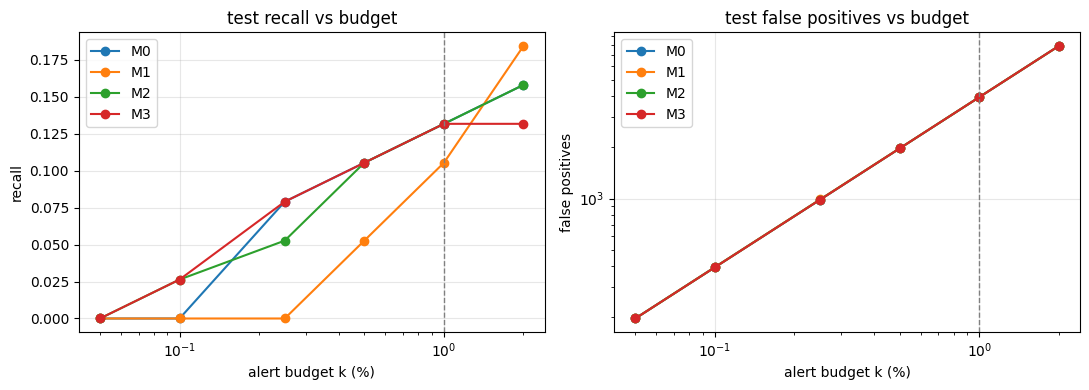

In [6]:
# ============================================================
# 5. Full budget curves, all configurations (test)
# ============================================================
curve_rows = []
for cfg in CONFIGS:
    g = mu.budget_grid(yt, S_TEST[cfg], K_GRID)
    g.insert(0, "config", cfg)
    curve_rows.append(g)
curves = pd.concat(curve_rows, ignore_index=True)
curves.to_csv(f"{WORK}/budget_curves_test.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for cfg in CONFIGS:
    g = curves[curves.config == cfg]
    ax[0].plot(g["k_pct"], g["recall"], "o-", label=cfg)
    ax[1].plot(g["k_pct"], g["fp"], "o-", label=cfg)
for a, ttl, yl in ((ax[0], "test recall vs budget", "recall"),
                   (ax[1], "test false positives vs budget", "false positives")):
    a.set_xscale("log"); a.axvline(K, color="grey", ls="--", lw=1)
    a.set_xlabel("alert budget k (%)"); a.set_title(ttl); a.set_ylabel(yl)
    a.legend(); a.grid(alpha=.3)
ax[1].set_yscale("log")
plt.tight_layout(); plt.savefig(f"{WORK}/fig_budget_curves_test.png", dpi=150); plt.show()

## 6. Report account alert coverage

The historical helper in this notebook classifies an account as positive when it has at least one labelled-positive day, then records whether that account receives any alert during the window. An alert on a benign day can therefore count towards this coverage measure.

This differs from requiring an alert on a labelled-malicious day. Do not use the two definitions interchangeably. The supplied Environment B evaluator in 7R-C records them separately.

Account false-positive rate is the share of accounts with no positive day that receive at least one alert. These account summaries complement, rather than replace, user-day recall.


In [7]:
# ============================================================
# 6. Account-level detection (pre-specified secondary), val + test
# ============================================================
acct_rows = []
for part in ("val", "test"):
    yp = scores_all.loc[MASK[part], "label"].to_numpy()
    up = scores_all.loc[MASK[part], "user"].to_numpy()
    for cfg in CONFIGS:
        sp = scores_all.loc[MASK[part], f"{cfg}_{DET}"].to_numpy()
        am = account_metrics(up, yp, mu.alerts_at_budget(sp, K))
        am.update({"partition": part, "config": cfg})
        acct_rows.append(am)
acct_tbl = pd.DataFrame(acct_rows)[
    ["partition", "config", "insider_accounts", "insider_alerted",
     "account_recall", "benign_accounts", "benign_alerted", "account_fpr"]]
acct_tbl.to_csv(f"{WORK}/account_level_metrics.csv", index=False)
print(f"account-level detection @ k={K}% (account alerted >= once in window):")
print(acct_tbl.to_string(index=False))

account-level detection @ k=1.0% (account alerted >= once in window):
partition config  insider_accounts  insider_alerted  account_recall  benign_accounts  benign_alerted  account_fpr
      val     M0                27               14        0.518519             3840             404     0.105208
      val     M1                27               11        0.407407             3840             335     0.087240
      val     M2                27               11        0.407407             3840             486     0.126562
      val     M3                27               19        0.703704             3840             360     0.093750
     test     M0                 2                1        0.500000             3739             402     0.107515
     test     M1                 2                1        0.500000             3739             329     0.087991
     test     M2                 2                1        0.500000             3739             471     0.125970
     test     M3  

## 7. Evaluate the feature-family ablations

Remove one M2 context family at a time: access level, category frequencies, expected-hours features or peer deviations. Each reduced representation is fitted separately and evaluated on validation data.

These are exploratory checks of the specified feature families. Removing a family also changes the fitted model and its dimensionality, so the results are not isolated causal effects of individual organisational concepts.

Notebook 5d later repeats these validation analyses under both the as-run and corrected label views. Neither set selects a replacement primary model from the test results.


In [8]:
# ============================================================
# 7. Ablations of M2's context groups — VALIDATION ONLY (exploratory;
#    the test partition is reserved for the pre-registered M0–M3 tables)
# ============================================================
peer_cols = [c for c in CTX_COLS["curated"] if c.endswith("_peer_z")]
ABLATE = {
    "no_access_level": ["access_level"],
    "no_cat_freq":     ["role_freq", "dept_freq"],
    "no_hours":        ["early_start_dev", "late_end_dev", "outside_expected_hours"],
    "no_peer_z":       peer_cols,
}
yv = scores_all.loc[MASK["val"], "label"].to_numpy()
ab_rows = []
for tag, base_cfg in (("M2_full", "M2"), ("M0_ref", "M0")):
    sv = scores_all.loc[MASK["val"], f"{base_cfg}_{DET}"].to_numpy()
    m = mu.metrics_from_counts(*mu.counts(yv, mu.alerts_at_budget(sv, K)))
    ab_rows.append({"variant": tag, "n_features": len(M0_FEATURES) +
                    (len(CTX_COLS["curated"]) if base_cfg == "M2" else 0),
                    "val_pr_auc": average_precision_score(yv, sv),
                    "val_recall_at_k": m["recall"], "val_fp_at_k": m["fp"]})
frame2, _ = build_frame("curated")
for tag, drop in ABLATE.items():
    t = time.time()
    cols = M0_FEATURES + [c for c in CTX_COLS["curated"] if c not in drop]
    X = mu.prepare_matrix(frame2, cols)
    models = mu.fit_detectors(X[MASK["train"]], seed=SEED)
    sv = mu.score_detectors(models, X)[DET][MASK["val"]]
    m = mu.metrics_from_counts(*mu.counts(yv, mu.alerts_at_budget(sv, K)))
    ab_rows.append({"variant": tag, "n_features": len(cols),
                    "val_pr_auc": average_precision_score(yv, sv),
                    "val_recall_at_k": m["recall"], "val_fp_at_k": m["fp"]})
    print(f"{tag}: refit+eval in {time.time()-t:,.0f}s")
    del X, models
del frame2
ab_tbl = pd.DataFrame(ab_rows)
ab_tbl.to_csv(f"{WORK}/ablation_validation.csv", index=False)
print("\nablation (validation, exploratory):")
print(ab_tbl.to_string(index=False))

no_access_level: refit+eval in 104s
no_cat_freq: refit+eval in 93s
no_hours: refit+eval in 92s
no_peer_z: refit+eval in 87s

ablation (validation, exploratory):
        variant  n_features  val_pr_auc  val_recall_at_k  val_fp_at_k
        M2_full          59    0.000667            0.150         4054
         M0_ref          41    0.000836            0.125         4055
no_access_level          58    0.000619            0.100         4056
    no_cat_freq          57    0.000764            0.150         4054
       no_hours          56    0.000805            0.125         4055
      no_peer_z          47    0.000904            0.150         4054


## 8. Inspect the M2 explanations and one selected case

SHapley Additive exPlanations (SHAP) is used with the fitted M2 Isolation Forest. The global summary reports mean absolute contributions over a seed-42 sample of at most 500 M2 test alerts, not the entire test population.

The local case is the benign test user-day alerted by M0 but not M2 with the largest percentile-rank reduction under M2. The cell prints its context values and saves the twelve largest absolute SHAP contributions.

These contributions explain the output handled by the M2 explainer. They are not a causal decomposition of the M2-minus-M0 score or rank change. In particular, the preserved printed phrase "negative = normalising" should not be treated as proof that a feature caused the alert to disappear without checking the explained output scale.

The section is skipped when the selected family is not Isolation Forest or SHAP is unavailable.


top-15 mean|SHAP| on M2 test alerts:
device_afterhours           0.481674
device_pcs                  0.400138
file_afterhours             0.398498
file_events_peer_z          0.390606
file_distinct               0.387748
file_to_removable           0.384706
device_connects_peer_z      0.371774
logoff_count                0.360254
outside_expected_hours      0.355254
file_events                 0.344111
device_connects             0.343998
file_to_removable_peer_z    0.343754
file_docs                   0.342883
logon_afterhours            0.319028
logon_pcs                   0.313258

CASE STUDY — benign day alerted by M0, suppressed by M2:
  user=SLB3039  day=2011-03-16  M0 rank 0.9921 -> M2 rank 0.9744
  top SHAP contributions (M2 anomaly score; negative = normalising):
logoff_count                   -1.218681
logon_afterhours               -1.216382
logon_pcs                      -1.154482
access_level                   -0.825945
logon_count                    -0.760445
first_logon

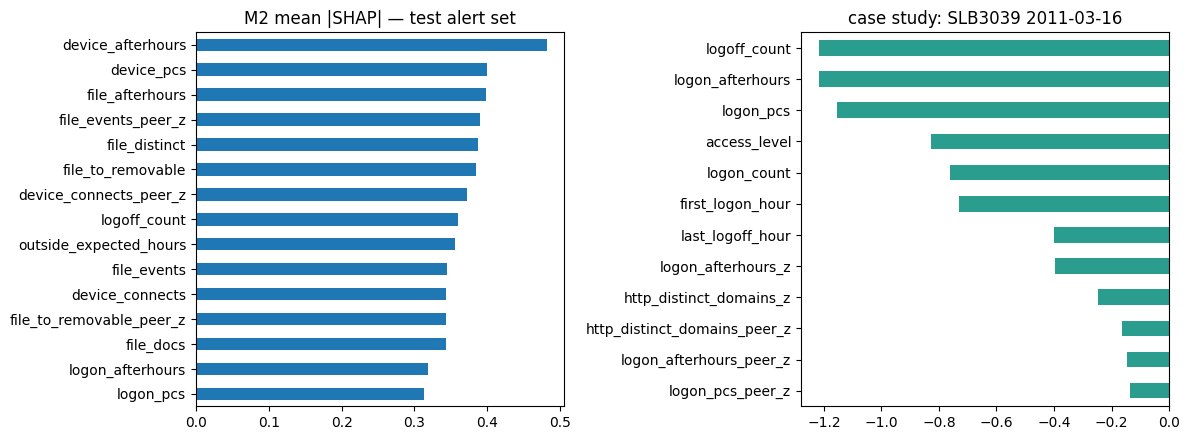

In [9]:
# ============================================================
# 8. SHAP — global attribution for M2 + one "M0 false positive
#    suppressed by M2" case study
# ============================================================
if DET != "if":
    print(f"NOTE: frozen detector is '{DET}'; TreeExplainer requires the "
          "IsolationForest. SHAP section skipped (KernelExplainer is "
          "impractical at this scale). Rankings above are unaffected.")
else:
    try:
        import shap
        frame2, cols2 = build_frame("curated")
        X2 = mu.prepare_matrix(frame2, cols2)
        X2s = FITTED["M2"]["scaler"].transform(X2[MASK["test"]]).astype("float32")
        expl = shap.TreeExplainer(FITTED["M2"]["iforest"])

        # (a) global: mean |SHAP| over the M2 test alert set (capped at 500 rows)
        idx_alert = np.where(ALERT["M2"])[0]
        rng = np.random.default_rng(SEED)
        take = rng.choice(idx_alert, min(500, len(idx_alert)), replace=False)
        sv_glob = expl.shap_values(X2s[take])
        imp = (pd.Series(np.abs(sv_glob).mean(axis=0), index=cols2)
                 .sort_values(ascending=False))
        print("top-15 mean|SHAP| on M2 test alerts:")
        print(imp.head(15).to_string())

        # (b) case study: benign test day alerted by M0 but NOT by M2, with the
        #     largest percentile-rank drop under M2
        r0 = pd.Series(S_TEST["M0"]).rank(pct=True).to_numpy()
        r2 = pd.Series(S_TEST["M2"]).rank(pct=True).to_numpy()
        cand = np.where(ALERT["M0"] & ~ALERT["M2"] & (yt == 0))[0]
        assert len(cand), "no suppressed-FP candidates found"
        case = cand[np.argmax(r0[cand] - r2[cand])]
        test_rows = scores_all.loc[MASK["test"]].reset_index(drop=True)
        who = test_rows.loc[case, ["user", "day"]]
        print(f"\nCASE STUDY — benign day alerted by M0, suppressed by M2:")
        print(f"  user={who['user']}  day={who['day'].date()}  "
              f"M0 rank {r0[case]:.4f} -> M2 rank {r2[case]:.4f}")
        sv_case = expl.shap_values(X2s[case:case+1])[0]
        contrib = pd.Series(sv_case, index=cols2)
        top = contrib.reindex(contrib.abs().sort_values(ascending=False).head(12).index)
        print("  top SHAP contributions (M2 anomaly score; negative = normalising):")
        print(top.to_string())
        ctx_vals = (frame2.loc[MASK["test"]].reset_index(drop=True)
                    .loc[case, CTX_COLS["curated"]])
        print("  context feature values on the day:")
        print(ctx_vals.to_string())
        pd.DataFrame({"feature": top.index, "shap": top.values}).to_csv(
            f"{WORK}/case_study_fp_suppressed.csv", index=False)

        fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
        imp.head(15)[::-1].plot.barh(ax=ax[0])
        ax[0].set_title("M2 mean |SHAP| — test alert set")
        top[::-1].plot.barh(ax=ax[1],
            color=["#2a9d8f" if v < 0 else "#e76f51" for v in top[::-1]])
        ax[1].set_title(f"case study: {who['user']} {who['day'].date()}")
        plt.tight_layout()
        plt.savefig(f"{WORK}/fig_shap_m2.png", dpi=150); plt.show()
        del frame2, X2, X2s
    except ImportError:
        print("NOTE: shap not installed in this image; section skipped.")

## 9. Describe false-positive rates by group

Summarise benign test user-days by access tier and, when the organisational file is attached, by role and department. The attributes are joined for this reporting step rather than added to an already fitted model.

The tables show where the existing alerts fall. A lower rate in one group does not establish a lower total false-alert burden, a fairness benefit or reduced investigation time. Missing attributes can also limit the population represented by a particular breakdown.

Notebook 5b supplies the later role and department reporting addendum.


In [10]:
# ============================================================
# 9. Subgroup FPR at the frozen budget (test) — ANALYSIS-ONLY join
# ============================================================
test_rows = scores_all.loc[MASK["test"], ["user", "day", "label"]].reset_index(drop=True)
test_rows["alert_M0"] = ALERT["M0"]
test_rows["alert_M2"] = ALERT["M2"]
test_rows = test_rows.merge(
    CTX["curated"][["user", "day", "access_level"]], on=["user", "day"], how="left")

def subgroup_fpr(df, by):
    ben = df[df.label == 0]
    g = ben.groupby(by).agg(days=("alert_M0", "size"),
                            fp_M0=("alert_M0", "sum"), fp_M2=("alert_M2", "sum"))
    g["fpr_M0"] = g.fp_M0 / g.days
    g["fpr_M2"] = g.fp_M2 / g.days
    g["d_fpr"] = g.fpr_M2 - g.fpr_M0
    return g.sort_values("days", ascending=False)

print("subgroup FPR by ACCESS LEVEL (benign test user-days):")
sg_access = subgroup_fpr(test_rows, "access_level")
print(sg_access.to_string())
sg_access.to_csv(f"{WORK}/subgroup_fpr_access.csv")

if P_LDAP:
    # attach role/department for REPORTING ONLY (mirrors NB3's SCD join; these
    # attributes are not used as features anywhere in this notebook)
    ldap = pd.read_parquet(P_LDAP)
    ldap["user_id"] = ldap["user_id"].astype(str)
    snap = (ldap[["user_id", "snapshot", "role", "department"]]
            .rename(columns={"user_id": "user", "snapshot": "month"}))
    snap["month"] = snap["month"].astype(str)
    test_rows["month"] = test_rows["day"].dt.to_period("M").astype(str)
    um = test_rows[["user", "month"]].drop_duplicates().merge(
        snap, on=["user", "month"], how="left").sort_values(["user", "month"])
    um[["role", "department"]] = um.groupby("user")[["role", "department"]].ffill()
    um[["role", "department"]] = um.groupby("user")[["role", "department"]].bfill()
    test_rows = test_rows.merge(um, on=["user", "month"], how="left")
    for by, fname in (("role", "subgroup_fpr_role.csv"),
                      ("department", "subgroup_fpr_department.csv")):
        sg = subgroup_fpr(test_rows, by)
        sg.to_csv(f"{WORK}/{fname}")
        print(f"\nsubgroup FPR by {by.upper()} (top 12 by exposure):")
        print(sg.head(12).to_string())
else:
    print("\nNOTE: ldap_monthly.parquet (NB1 output) not attached — role/department "
          "subgroups skipped; access-level table above stands.")

subgroup FPR by ACCESS LEVEL (benign test user-days):
                days  fp_M0  fp_M2    fpr_M0    fpr_M2     d_fpr
access_level                                                    
1.0           338178   1678   2021  0.004962  0.005976  0.001014
2.0            47701    809    812  0.016960  0.017023  0.000063
3.0             9632   1463   1117  0.151890  0.115968 -0.035922

NOTE: ldap_monthly.parquet (NB1 output) not attached — role/department subgroups skipped; access-level table above stands.


## 10. Record the primary decision

Apply the two M2-versus-M0 criteria and save their values, policy and negative-control flag in `verdict.json`. M1 is a supporting comparator and does not determine the M2 verdict.

The retained run reports H1 not supported. The code also contains a legacy "H1 PARTIALLY SUPPORTED" branch for a favourable point estimate whose interval includes zero. That branch does not meet the dissertation's stated requirement for supported improvement.

Likewise, the stored M3 variable `leak_flag` is a warning to investigate a favourable shuffled-control result, not a diagnosis of leakage. The code and its historical wording are unchanged.


In [11]:
# ============================================================
# 10. Pre-registered verdict (criteria fixed in Ch.3 + NB4 policy;
#     operationalisation documented in the markdown above)
# ============================================================
def sig_better(d, direction):
    """95% CI excludes 0 in the improving direction."""
    return (d["ci_hi"] < 0) if direction == "neg" else (d["ci_lo"] > 0)

m2b, m2m = paired["M2"]["budget"], paired["M2"]["matched"]
m3b, m3m = paired["M3"]["budget"], paired["M3"]["matched"]

critA = sig_better(m2m, "neg")                       # lower FPR at matched recall
critB = sig_better(m2b["recall"], "pos")             # more TPs at the fixed budget
pointA, pointB = m2m["point"] < 0, m2b["recall"]["point"] > 0
leak_flag = (sig_better(m3m, "neg") or sig_better(m3b["recall"], "pos"))

if critA or critB:
    verdict = "H1 SUPPORTED"
elif pointA or pointB:
    verdict = "H1 PARTIALLY SUPPORTED (point improvement; CI includes 0)"
else:
    verdict = "H1 NOT SUPPORTED"

print("=" * 64)
print("PRE-REGISTERED VERDICT — M2 (curated BI context) vs M0 (baseline)")
print("=" * 64)
print(f"Criterion A — FPR at matched recall (anchor {ANCHOR:.3f}):")
print(f"  dFPR = {m2m['point']:+.5f}  CI95 [{m2m['ci_lo']:+.5f}, {m2m['ci_hi']:+.5f}]"
      f"  -> {'SIGNIFICANT' if critA else 'not significant'}")
print(f"Criterion B — recall at fixed budget k={K}%:")
print(f"  drecall = {m2b['recall']['point']:+.5f}  "
      f"CI95 [{m2b['recall']['ci_lo']:+.5f}, {m2b['recall']['ci_hi']:+.5f}]"
      f"  -> {'SIGNIFICANT' if critB else 'not significant'}")
print(f"Negative control (M3 vs M0): "
      f"{'FLAG — investigate leakage' if leak_flag else 'PASS (no significant improvement)'}")
print(f"Raw-categorical comparator (M1 vs M0, Tuor et al. engagement): "
      f"drecall@k = {paired['M1']['budget']['recall']['point']:+.5f}, "
      f"dFPR@matched = {paired['M1']['matched']['point']:+.5f}")
print("-" * 64)
print(f"VERDICT: {verdict}")
print("=" * 64)
json.dump({"verdict": verdict, "criterion_A_matched_fpr": m2m,
           "criterion_B_budget": m2b, "anchor_recall": ANCHOR,
           "negative_control_flag": bool(leak_flag),
           "policy": {"detector": DET, "k_pct": K}, "seed": SEED},
          open(f"{WORK}/verdict.json", "w"), indent=2, default=float)

PRE-REGISTERED VERDICT — M2 (curated BI context) vs M0 (baseline)
Criterion A — FPR at matched recall (anchor 0.132):
  dFPR = +0.00108  CI95 [-0.00022, +0.00348]  -> not significant
Criterion B — recall at fixed budget k=1.0%:
  drecall = +0.00000  CI95 [+0.00000, +0.00000]  -> not significant
Negative control (M3 vs M0): PASS (no significant improvement)
Raw-categorical comparator (M1 vs M0, Tuor et al. engagement): drecall@k = -0.02632, dFPR@matched = +0.00706
----------------------------------------------------------------
VERDICT: H1 NOT SUPPORTED


## 11. Check the completed comparison

Review the reported input and policy checks, the common observations, the reused M0 scores and the saved output inventory.

A successful integrity check supports the declared processing rules. It does not erase the label-attribution, test-preview, dimensionality or control limitations discussed in the notes and dissertation.


In [12]:
# ============================================================
# 11. Integrity audit + outputs
# ============================================================
print("M0–M3 COMPARISON INTEGRITY AUDIT")
print("-" * 64)
print(f"1. Shared logic imported VERBATIM from NB4 output "
      f"(modelling_utils.py sha256[:16]={UTILS_SHA}); NB5 adds evaluation-only helpers.")
print(f"2. Policy (detector={DET}, k={K}%) LOADED from NB4's threshold_policy.json —")
print(f"   chosen on validation in NB4; NB5 makes no model/threshold choices.")
print(f"3. M0 scores reused from NB4's committed scores_m0.parquet (not refitted).")
print(f"4. M1/M2/M3 fitted on the train partition only "
      f"({int(MASK['train'].sum()):,} rows), identical code path for all.")
print(f"5. Context files verified label-free on load; identical (user, day) spine.")
print(f"6. Ablations evaluated on VALIDATION only; the test partition appears only")
print(f"   in the pre-registered comparison, curves, account, subgroup and verdict cells.")
print(f"7. SEED={SEED} everywhere; paired bootstraps resample users jointly.")
print("-" * 64)
print(f"\ntotal runtime: {(time.time() - T0) / 60:.1f} min")
print("\nfiles in /kaggle/working:")
for f in sorted(os.listdir(WORK)):
    p = f"{WORK}/{f}"
    if os.path.isfile(p):
        print(f"  {f:38s} {os.path.getsize(p)/1e6:8,.1f} MB")

M0–M3 COMPARISON INTEGRITY AUDIT
----------------------------------------------------------------
1. Shared logic imported VERBATIM from NB4 output (modelling_utils.py sha256[:16]=147d19b0977c79e8); NB5 adds evaluation-only helpers.
2. Policy (detector=if, k=1.0%) LOADED from NB4's threshold_policy.json —
   chosen on validation in NB4; NB5 makes no model/threshold choices.
3. M0 scores reused from NB4's committed scores_m0.parquet (not refitted).
4. M1/M2/M3 fitted on the train partition only (592,378 rows), identical code path for all.
5. Context files verified label-free on load; identical (user, day) spine.
6. Ablations evaluated on VALIDATION only; the test partition appears only
   in the pre-registered comparison, curves, account, subgroup and verdict cells.
7. SEED=42 everywhere; paired bootstraps resample users jointly.
----------------------------------------------------------------

total runtime: 12.8 min

files in /kaggle/working:
  __notebook__.ipynb                      